<a href="https://colab.research.google.com/github/242236/machine-learning-titanic/blob/main/Evaluacion_Machine_Learning_Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluación Unidad 1 – Machine Learning

## Análisis y preparación de datos: Titanic

**Asignatura:** Machine Learning  
**Estudiante:** Carolina Cid Jara  
**Carrera:** Ingeniería Civil Industrial  
**Institución:** Universidad Mayor  
**Docente:** Franco Mansilla  
**Fecha:** Agosto 2026

# Introducción

El Machine Learning permite desarrollar sistemas capaces de aprender a partir de datos. Sin embargo, antes de aplicar modelos de aprendizaje automático es fundamental comprender, explorar y preparar adecuadamente la información disponible.

En esta evaluación se trabajará con el dataset Titanic, que contiene información sobre los pasajeros del barco y permite analizar distintas características asociadas a ellos.

El desarrollo considera la revisión de frameworks de analítica de datos, la exploración y limpieza de la base de datos, el tratamiento de valores faltantes y datos atípicos, y la comparación de diferentes métodos para dividir los datos en conjuntos de entrenamiento, validación y prueba.

Finalmente, el trabajo será almacenado en un repositorio de GitHub, con el propósito de mantener un registro del desarrollo y favorecer su reproducibilidad.

# 1. Frameworks de analítica de datos

Los frameworks de analítica de datos proporcionan una estructura para organizar las diferentes etapas de un proyecto de análisis de datos y Machine Learning. Permiten trabajar de manera ordenada desde la comprensión del problema y los datos hasta la preparación, modelamiento y evaluación de los resultados.

A continuación, se presentan tres frameworks utilizados en proyectos de analítica de datos.

## CRISP-DM

CRISP-DM (Cross-Industry Standard Process for Data Mining) organiza un proyecto de analítica en diferentes etapas: comprensión del negocio, comprensión de los datos, preparación de los datos, modelamiento, evaluación y despliegue.

**Alcance:** permite estructurar un proyecto completo de analítica de datos, desde la definición del problema hasta la utilización de los resultados.

**Limitación:** es un proceso general y puede requerir adaptaciones dependiendo del tipo de proyecto y de las características de los datos.

## KDD

KDD (Knowledge Discovery in Databases) corresponde a un proceso orientado al descubrimiento de conocimiento a partir de los datos. Considera etapas como selección de datos, preprocesamiento, transformación, minería de datos e interpretación de los resultados.

**Alcance:** permite transformar grandes cantidades de datos en información y conocimiento útil.

**Limitación:** se encuentra principalmente orientado al análisis y descubrimiento de patrones en los datos, por lo que aborda con menor detalle aspectos relacionados con la implementación final de una solución.

## SEMMA

SEMMA corresponde a las etapas Sample, Explore, Modify, Model y Assess. Su objetivo es organizar el proceso analítico mediante la selección de una muestra, exploración de los datos, modificación o preparación, modelamiento y evaluación.

**Alcance:** entrega una estructura clara para explorar, preparar y modelar datos.

**Limitación:** se concentra principalmente en las etapas técnicas del análisis y modelamiento, considerando con menor profundidad la comprensión inicial del problema de negocio.

# 2. Calidad de datos: análisis y preparación del dataset Titanic

En esta etapa se realizará una exploración inicial del dataset Titanic con el objetivo de conocer su estructura e identificar posibles problemas de calidad de los datos.

Se analizarán los valores faltantes y los posibles valores atípicos, aplicando posteriormente un tratamiento adecuado según las características de cada variable.

In [1]:
import pandas as pd

datos = pd.read_csv("train.csv")

datos.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
datos.shape

(891, 12)

In [3]:
datos.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [4]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
datos.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [6]:
datos["Age"].median()

28.0

In [7]:
datos["Age"] = datos["Age"].fillna(datos["Age"].median())

In [8]:
datos["Age"].isnull().sum()

np.int64(0)

In [9]:
datos["Embarked"].value_counts()

,count
Embarked,
S,644
C,168
Q,77


In [10]:
datos["Embarked"] = datos["Embarked"].fillna("S")

In [11]:
datos["Embarked"].isnull().sum()

np.int64(0)

In [12]:
datos = datos.drop(columns=["Cabin"])

In [13]:
datos.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked'],
      dtype='object')

In [14]:
datos.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


## Tratamiento de valores faltantes

Durante la exploración de la base de datos se identificaron valores faltantes en las variables Age, Cabin y Embarked.

- Age presentaba 177 valores faltantes. Estos fueron reemplazados por la mediana de las edades, correspondiente a 28 años.
- Embarked presentaba 2 valores faltantes. Al ser una variable categórica, estos fueron reemplazados por la categoría más frecuente (S).
- Cabin presentaba 687 valores faltantes de un total de 891 registros. Debido a la gran cantidad de información ausente, se decidió eliminar esta variable.

Finalmente, se verificó nuevamente la base de datos, obteniendo 0 valores faltantes en las variables restantes.

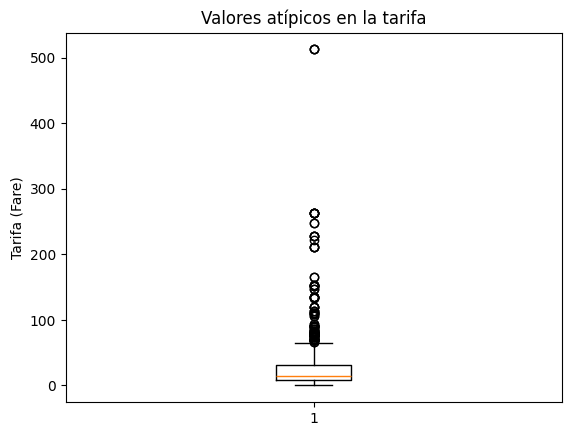

In [15]:
import matplotlib.pyplot as plt

plt.boxplot(datos["Fare"])
plt.title("Valores atípicos en la tarifa")
plt.ylabel("Tarifa (Fare)")
plt.show()

In [16]:
Q1 = datos["Fare"].quantile(0.25)
Q3 = datos["Fare"].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

Límite inferior: -26.724
Límite superior: 65.6344


In [17]:
outliers = datos[datos["Fare"] > limite_superior]

print("Cantidad de valores atípicos:", len(outliers))

Cantidad de valores atípicos: 116


## Identificación y tratamiento de valores atípicos

Para identificar posibles valores atípicos se analizó la variable Fare, que representa la tarifa pagada por los pasajeros.

Primero se utilizó un gráfico de caja (boxplot), donde se observaron varios valores alejados de la distribución principal. Posteriormente, se aplicó el método del rango intercuartílico (IQR).

El límite superior obtenido fue de 65,63, identificándose 116 registros por sobre este valor.

Estos registros no fueron eliminados, ya que las tarifas elevadas pueden corresponder a situaciones reales, como pasajeros que pagaron valores superiores por sus pasajes. Por lo tanto, se decidió conservar estos datos para no eliminar información potencialmente relevante.

# 3. Ventanas de desarrollo, validación y test

La división de los datos en conjuntos de entrenamiento, validación y prueba permite evaluar de manera más confiable el desempeño de un modelo de Machine Learning.

- Entrenamiento (train): corresponde a los datos utilizados para que el modelo aprenda.
- Validación (validation): permite evaluar y ajustar el modelo durante su desarrollo.
- Prueba (test): corresponde a datos que el modelo no ha utilizado durante su entrenamiento y permite realizar una evaluación final.

Para seleccionar una estrategia adecuada para el dataset Titanic, se analizarán tres métodos de división: Holdout aleatorio, validación cruzada y división temporal.

## Comparación de métodos

### 1. Holdout aleatorio
Este método divide aleatoriamente la base de datos en conjuntos independientes de entrenamiento, validación y prueba.

Ventaja: es sencillo de implementar y requiere poco tiempo de procesamiento.

Desventaja: los resultados pueden variar dependiendo de cómo se realice la división aleatoria.

### 2. Validación cruzada (Cross-validation)
Este método divide los datos en varios subconjuntos y realiza diferentes combinaciones de entrenamiento y validación.

Ventaja: permite realizar una evaluación más robusta, ya que utiliza diferentes particiones de los datos.

Desventaja: requiere mayor tiempo y procesamiento porque el procedimiento se repite varias veces.

### 3. División temporal
Este método divide los datos respetando un orden cronológico, utilizando datos anteriores para entrenamiento y datos posteriores para validación y prueba.

Ventaja: es apropiado cuando los datos poseen un orden temporal.

Desventaja: no es adecuado cuando la base de datos no posee una dimensión temporal relevante.

## Método seleccionado

Para el dataset Titanic se seleccionó el método Holdout aleatorio.

Esta decisión se tomó debido a que los registros de pasajeros no corresponden a una serie temporal que requiera mantener un orden cronológico. Además, este método permite realizar una división sencilla y clara de los datos.

Se utilizará la siguiente distribución:

- 70% para entrenamiento.
- 15% para validación.
- 15% para prueba.

In [18]:
X = datos.drop(columns=["Survived"])
y = datos["Survived"]

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

In [21]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

In [22]:
print("Entrenamiento:", len(X_train))
print("Validación:", len(X_val))
print("Prueba:", len(X_test))

Entrenamiento: 623
Validación: 134
Prueba: 134


## Resultado de la división

Se aplicó el método Holdout aleatorio utilizando una distribución aproximada de 70% para entrenamiento, 15% para validación y 15% para prueba.

Como resultado, los 891 registros fueron distribuidos de la siguiente manera:

- Entrenamiento: 623 registros.
- Validación: 134 registros.
- Prueba: 134 registros.

Se utilizó random_state=42 para mantener la misma división cada vez que se ejecute el código, favoreciendo la reproducibilidad del análisis.

De esta manera, el conjunto de entrenamiento será utilizado para el aprendizaje del modelo, el conjunto de validación para evaluar y ajustar su desarrollo, y el conjunto de prueba quedará reservado para la evaluación final.

# 4. Repositorio GitHub

Para mantener la trazabilidad y reproducibilidad del proyecto, el desarrollo de esta evaluación se almacenó en un repositorio de GitHub.

**Repositorio del proyecto:**  
https://github.com/242236/machine-learning-titanic

El notebook desarrollado en Google Colab fue guardado en GitHub, permitiendo mantener una copia del código y un registro de los cambios realizados durante el desarrollo de la evaluación.

# Conclusión

En esta evaluación se desarrolló un proceso de análisis y preparación de datos utilizando el dataset Titanic, aplicando conceptos fundamentales de Machine Learning y analítica de datos.

En primer lugar, se revisaron distintos frameworks de analítica de datos, considerando sus principales características, alcances y limitaciones. Posteriormente, se realizó una exploración del dataset para conocer su estructura e identificar problemas relacionados con la calidad de los datos.

Durante la etapa de limpieza se identificaron valores faltantes en las variables Age, Cabin y Embarked. Los valores faltantes de Age fueron reemplazados por la mediana, los de Embarked por la categoría más frecuente y la variable Cabin fue eliminada debido a la gran cantidad de información ausente.

También se analizaron posibles valores atípicos en la variable Fare mediante un gráfico de caja y el método IQR. Se identificaron 116 posibles valores atípicos, los cuales se conservaron debido a que pueden corresponder a tarifas reales pagadas por los pasajeros.

Finalmente, se compararon diferentes métodos para generar conjuntos de entrenamiento, validación y prueba. Para este dataset se seleccionó el método Holdout aleatorio, obteniendo 623 registros para entrenamiento, 134 para validación y 134 para prueba. Además, el desarrollo fue almacenado en un repositorio de GitHub con el objetivo de favorecer su trazabilidad y reproducibilidad.

El desarrollo de esta evaluación permitió comprender la importancia de explorar, limpiar y dividir correctamente los datos antes de utilizarlos en un proyecto de Machine Learning.

# Bibliografía

- Aggarwal, C. C. (2017). *Outlier Analysis* (2.ª ed.). Springer.

- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O’Reilly Media.

- Hastie, T., Tibshirani, R. & Friedman, J. (2009). *The Elements of Statistical Learning: Data Mining, Inference, and Prediction* (2.ª ed.). Springer.

- Little, R. J. A. & Rubin, D. B. (2019). *Statistical Analysis with Missing Data* (3.ª ed.). Wiley.

- Loeliger, J. & McCullough, M. (2012). *Version Control with Git: Powerful Tools and Techniques for Collaborative Software Development*. O’Reilly Media.

- Kaggle. (s. f.). *Titanic - Machine Learning from Disaster*. Kaggle.

- Material de estudio Unidad 1. Machine Learning. Escuela de Ingeniería.

- Fayyad, U., Piatetsky-Shapiro, G. & Smyth, P. (1996). Knowledge Discovery and Data Mining: Towards a Unifying Framework. Proceedings of the Second International Conference on Knowledge Discovery and Data Mining, 82–88.

- SAS Institute Inc. (s. f.). Data Mining and SEMMA. SAS Documentation.

- Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C. & Wirth, R. (2000). CRISP-DM 1.0: Step-by-step data mining guide. SPSS.